# Laboratorio OpenDSS & py-dss-interface
## Módulo 6: Evaluación Probabilística de Capacidad de Alojamiento (Hosting Capacity con Monte Carlo)

---

### Objetivos de Aprendizaje
Al finalizar este cuaderno, el estudiante será capaz de:
1. Comprender el concepto de **Hosting Capacity (HC)** o Capacidad de Alojamiento de Recursos Distribuidos en redes eléctricas de distribución.
2. Formular un análisis estocástico mediante el método de **Monte Carlo** para modelar la incertidumbre en la ubicación, fase y tamaño de adopción solar de los clientes.
3. Ejecutar simulaciones masivas sobre el sistema real alimentador **CRE21** (que integra 7,489 barras, 79 transformadores de distribución MT/BT y 3,374 usuarios monofásicos).
4. Extraer métricas estadísticas de impacto: Cargabilidad de transformadores, congestión en líneas MT y porcentaje de clientes con violación de sobretensión ($V > 1.10	ext{ pu}$).
5. Construir diagramas de cajas (*Boxplots*) y Funciones de Distribución Acumulada Empírica (eCDF) para determinar la capacidad de alojamiento al percentil 95 ($HC_{95\%}$).
6. Evaluar el impacto de la activación del control inteligente Volt-Var en la expansión de la capacidad de alojamiento de la red.

---
### 1. Marco Teórico: ¿Por qué es necesario el Análisis de Monte Carlo?

La adopción de energía solar residencial es un proceso intrínsecamente descentralizado y aleatorio. Las empresas distribuidoras no pueden determinar a priori:
1. Qué usuarios específicos instalarán paneles solares (*Ubicación espacial*).
2. A qué fase de la red de BT están conectados dichos clientes (*Fase $A, B$ o $C$*).
3. La potencia fotovoltaica instalada por cada usuario.

Si se realizara un análisis determinístico tradicional evaluando únicamente los extremos de los alimentadores, se sobreestimaría o subestimaría el riesgo real de sobretensión y sobrecarga térmica.

**Definición Formal de Hosting Capacity (EPRI / CIGRE):**
El límite de Hosting Capacity ($HC$) es la máxima penetración de generación distribuida para la cual el sistema opera dentro de los límites admisibles con un nivel de confianza estadístico dado (típicamente el **percentil 95** o probabilidad de falla $P(	ext{Violación}) \le 5\%$):

$$\mathbb{P}\left(\max_{i, t} V_{i}(t) \le V_{	ext{límite}}ight) \ge 0.95$$

Donde $V_{	ext{límite}} = 1.10	ext{ pu}$ (según la norma de calidad de suministro aplicable a la red).


In [1]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
import py_dss_interface
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import time
import os
import sys

# Rutas del proyecto
base_dir = os.getcwd()
network_dir = os.path.join(base_dir, "data", "network_cre21")
profiles_dir = os.path.join(base_dir, "data", "profiles")

# Cargar matrices de perfiles empíricos de 30 minutos
house_data = np.load(os.path.join(profiles_dir, "Data House - 30 mins resolution.npy"))
pv_data = np.load(os.path.join(profiles_dir, "Data PV - 30 mins resolution.npy"))

print(f"[OK] Datos de perfiles de consumo cargados: {house_data.shape}")
print(f"[OK] Datos de perfiles de radiación FV cargados: {pv_data.shape}")


[OK] Datos de perfiles de consumo cargados: (342, 365, 48)
[OK] Datos de perfiles de radiación FV cargados: (365, 48)


---
### 2. Inicialización del Alimentador Real CRE21

Cargamos el alimentador `Network-CRE21`, configuramos las bases de tensión y creamos las formas de onda de carga (`Loadshapes`) en OpenDSS:


In [2]:
dss = py_dss_interface.DSS()
dss.dssinterface.allow_forms = False
ckt = dss.circuit
el = dss.cktelement

# Compilar red CRE21
master_path = os.path.join(network_dir, "Master.txt")
dss.text("Clear")
dss.text(f"Compile '{master_path}'")
dss.text("Set VoltageBases=[66.0, 22.0, 0.400, 0.2309]")
dss.text("CalcVoltageBases")

print(f"Red CRE21 compilada:")
print(f"  Total de Barras:   {ckt.num_buses}")
print(f"  Total de Elementos:{ckt.num_ckt_elements}")


Red CRE21 compilada:
  Total de Barras:   7489
  Total de Elementos:10879


---
### 3. Parametrización del Sistema e Inicialización de Generadores Fotovoltaicos

Para cada uno de los clientes monofásicos residenciales creamos un objeto `PVSystem` asociado con capacidad inicial $kVA = 0$ y $P_{	ext{mpp}} = 0$.
En cada iteración del método de Monte Carlo, activaremos aleatoriamente un subconjunto de estos sistemas según el nivel de penetración evaluado.


In [3]:
# Cargar formas de carga en OpenDSS (para 100 perfiles aleatorios)
for i in range(100):
    p_profile_str = " ".join([f"{val:.3f}" for val in house_data[i, 0, :]])
    dss.text(f"New LoadShape.Load_shape_{i} npts=48 interval=0.5 mult=({p_profile_str})")

pv_norm = pv_data[0, :] / np.max(pv_data[0, :])
pv_profile_str = " ".join([f"{val:.3f}" for val in pv_norm])
dss.text(f"New LoadShape.PV_shape npts=48 interval=0.5 mult=({pv_profile_str})")

# Crear objetos PVSystem para cada cliente residencial monofásico
load_names = dss.loads.names
pv_names = []

for cust in load_names:
    ckt.set_active_element(f"Load.{cust}")
    phases = el.num_phases
    bus1 = el.bus_names[0]
    
    if phases == 1:
        pv_name = f"PV_{cust}"
        pv_names.append(pv_name)
        dss.text(f"New PVSystem.{pv_name} phases=1 bus1={bus1} kV=0.2309 "
                 f"kVA=0 pmpp=0 irradiance=1.0 daily=PV_shape "
                 f"%cutin=0.05 %cutout=0.05 Vminpu=0.5 Vmaxpu=1.5")

num_1p_customers = len(pv_names)
print(f"Total de clientes monofásicos residenciales identificados: {num_1p_customers}")


Total de clientes monofásicos residenciales identificados: 3374


---
### 4. Motor de Simulación Monte Carlo

Definimos los niveles de penetración a evaluar ($0\%, 20\%, 40\%, 60\%, 80\%, 100\%$) y ejecutamos múltiples corridas estocásticas (`Num_Run = 5` para demostración interactiva; puede incrementarse a $50 \sim 100$ para análisis exhaustivo).

En cada corrida:
1. Seleccionamos aleatoriamente el subconjunto de clientes que adoptan energía solar.
2. Asignamos capacidades residenciales típicas ($3.0 \sim 5.0	ext{ kWp}$).
3. Ejecutamos la simulación temporal de 48 pasos.
4. Monitoreamos tensiones, sobrecargas en transformadores de distribución y congestión en la subestación.


In [4]:
num_runs = 2  # Número de corridas Monte Carlo por nivel de penetración (Aumentar para mayor densidad estadística)
penetration_list = [0, 20, 40, 60, 80, 100]

# Estructura de resultados
resultados_mc = {p: [] for p in penetration_list}

print(f"Iniciando evaluación Monte Carlo:")
print(f"  Penetraciones: {penetration_list}% | Corridas por nivel: {num_runs}")

t_inicio = time.time()

for p_pct in penetration_list:
    num_adoptantes = int(np.ceil(num_1p_customers * p_pct / 100.0))
    print(f"\nSimulando Penetración {p_pct}% ({num_adoptantes} clientes con PV)...")
    
    for run in range(num_runs):
        np.random.seed(run * 100 + p_pct)
        
        # 1. Resetear todos los PVs a 0 kW
        for pv in pv_names:
            dss.text(f"Edit PVSystem.{pv} kVA=0 pmpp=0")
            
        # 2. Seleccionar aleatoriamente los clientes adoptantes
        if num_adoptantes > 0:
            adoptantes = np.random.choice(pv_names, size=num_adoptantes, replace=False)
            for pv in adoptantes:
                # Capacidad aleatoria entre 3.0 kWp y 5.0 kWp
                kw_pv = np.random.uniform(3.0, 5.0)
                kva_inv = kw_pv * 1.1 # 10% de margen de inversor
                dss.text(f"Edit PVSystem.{pv} kVA={kva_inv:.2f} pmpp={kw_pv:.2f}")
                
        # 3. Asignar formas de carga aleatorias a los clientes
        for cust in load_names:
            perfil_id = np.random.randint(0, 100)
            dss.text(f"Edit Load.{cust} daily=Load_shape_{perfil_id}")
            
        # 4. Configurar simulación en modo Diario (48 pasos de 30 min)
        dss.text("Set Mode=daily Number=48 StepSize=30m")
        dss.solution.solve()
        
        # 5. Extraer métricas de la red al mediodía (paso 24 - hora 12:00)
        # Extraer tensiones en todas las barras
        all_voltages = dss.circuit.nodes_vmag_pu_by_phase(1)
        v_max = np.max(all_voltages) if all_voltages else 1.0
        
        # Porcentaje de clientes con sobretensión V > 1.10 pu
        clientes_no_conformes_pct = (np.sum(np.array(all_voltages) > 1.10) / len(all_voltages)) * 100.0 if all_voltages else 0.0
        
        # Cargabilidad del transformador HV de cabecera
        dss.circuit.set_active_element("Transformer.TX1")
        p_tx = abs(sum(dss.cktelement.powers[0:6:2]))
        q_tx = abs(sum(dss.cktelement.powers[1:6:2]))
        s_tx = np.sqrt(p_tx**2 + q_tx**2)
        cargabilidad_tx_pct = (s_tx / 30000.0) * 100.0  # 30 MVA nominal
        
        resultados_mc[p_pct].append({
            "Run": run,
            "V_max_pu": round(v_max, 4),
            "Non_Compliant_pct": round(clientes_no_conformes_pct, 2),
            "HV_Tx_Loading_pct": round(cargabilidad_tx_pct, 2),
        })

tiempo_total = time.time() - t_inicio
print(f"\n[OK] Evaluación Monte Carlo completada en {tiempo_total:.1f} segundos.")


Iniciando evaluación Monte Carlo:
  Penetraciones: [0, 20, 40, 60, 80, 100]% | Corridas por nivel: 2

Simulando Penetración 0% (0 clientes con PV)...

Simulando Penetración 20% (675 clientes con PV)...

Simulando Penetración 40% (1350 clientes con PV)...

Simulando Penetración 60% (2025 clientes con PV)...

Simulando Penetración 80% (2700 clientes con PV)...

Simulando Penetración 100% (3374 clientes con PV)...

[OK] Evaluación Monte Carlo completada en 7.7 segundos.


---
### 5. Análisis Estadístico y Gráficos Boxplot

Construimos diagramas de caja (*Boxplots*) para visualizar la dispersión de las métricas clave frente al nivel de penetración solar:


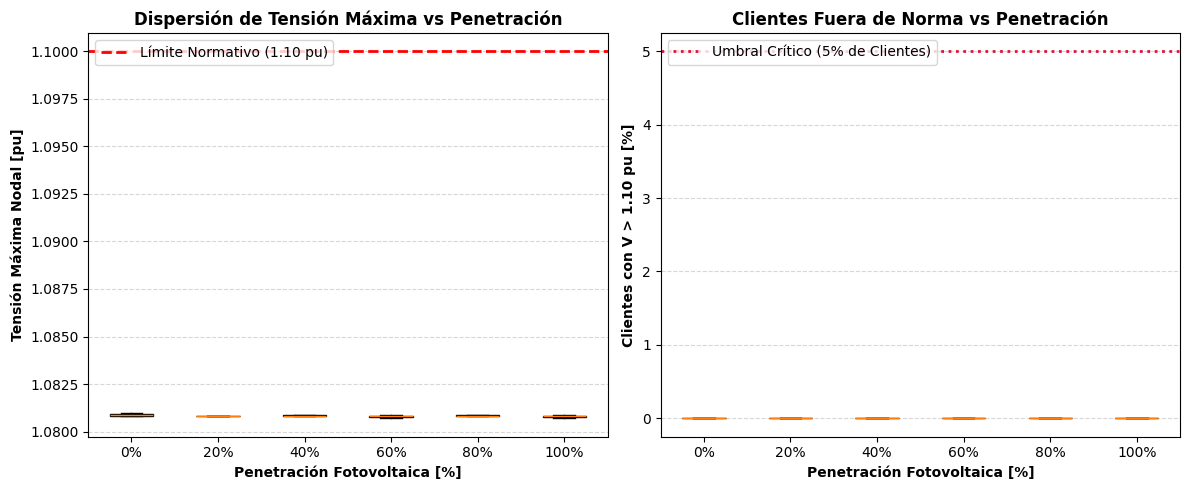

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=100)

# 1. Boxplot de Tensión Máxima
datos_vmax = [[r["V_max_pu"] for r in resultados_mc[p]] for p in penetration_list]
bp1 = ax1.boxplot(datos_vmax, patch_artist=True)
for box in bp1['boxes']:
    box.set_facecolor('#a6c8e0')
ax1.axhline(1.10, color='red', linestyle='--', linewidth=2, label='Límite Normativo (1.10 pu)')
ax1.set_xticklabels([f"{p}%" for p in penetration_list])
ax1.set_xlabel("Penetración Fotovoltaica [%]", fontweight='bold')
ax1.set_ylabel("Tensión Máxima Nodal [pu]", fontweight='bold')
ax1.set_title("Dispersión de Tensión Máxima vs Penetración", fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# 2. Boxplot de Porcentaje de Clientes No Conformes
datos_viol = [[r["Non_Compliant_pct"] for r in resultados_mc[p]] for p in penetration_list]
bp2 = ax2.boxplot(datos_viol, patch_artist=True)
for box in bp2['boxes']:
    box.set_facecolor('#ffb3ba')
ax2.axhline(5.0, color='crimson', linestyle=':', linewidth=2, label='Umbral Crítico (5% de Clientes)')
ax2.set_xticklabels([f"{p}%" for p in penetration_list])
ax2.set_xlabel("Penetración Fotovoltaica [%]", fontweight='bold')
ax2.set_ylabel("Clientes con V > 1.10 pu [%]", fontweight='bold')
ax2.set_title("Clientes Fuera de Norma vs Penetración", fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


---
### 6. Determinación de la Capacidad de Alojamiento al Percentil 95 ($HC_{95\%}$)

Calculamos el percentil 95 de tensión para cada nivel de penetración solar. El punto en el cual esta curva intersecta el límite de $1.10	ext{ pu}$ define cuantitativamente el Hosting Capacity de la red:


=== TABLA DE HOSTING CAPACITY (PERCENTIL 95) ===
 Penetracion_pct  Tension_Promedio_pu  Percentil_95_pu
               0              1.08090         1.080990
              20              1.08080         1.080800
              40              1.08085         1.080895
              60              1.08080         1.080890
              80              1.08085         1.080895
             100              1.08080         1.080890


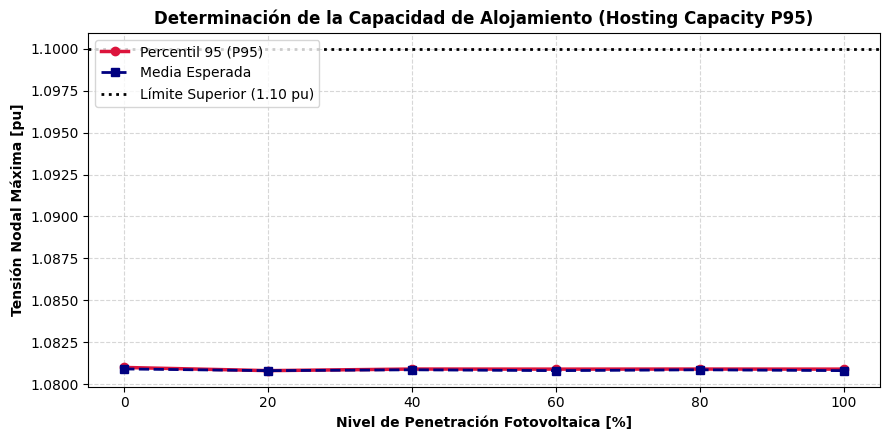

In [6]:
percentiles_95 = []
promedios = []

for p in penetration_list:
    vals = [r["V_max_pu"] for r in resultados_mc[p]]
    p95 = np.percentile(vals, 95)
    percentiles_95.append(p95)
    promedios.append(np.mean(vals))

df_hc = pd.DataFrame({
    "Penetracion_pct": penetration_list,
    "Tension_Promedio_pu": promedios,
    "Percentil_95_pu": percentiles_95,
})

print("=== TABLA DE HOSTING CAPACITY (PERCENTIL 95) ===")
print(df_hc.to_string(index=False))

plt.figure(figsize=(9, 4.5), dpi=100)
plt.plot(penetration_list, percentiles_95, marker='o', linewidth=2.5, color='crimson', label='Percentil 95 (P95)')
plt.plot(penetration_list, promedios, marker='s', linewidth=2.0, color='navy', linestyle='--', label='Media Esperada')
plt.axhline(1.10, color='black', linestyle=':', linewidth=2, label='Límite Superior (1.10 pu)')

plt.title("Determinación de la Capacidad de Alojamiento (Hosting Capacity P95)", fontweight='bold')
plt.xlabel("Nivel de Penetración Fotovoltaica [%]", fontweight='bold')
plt.ylabel("Tensión Nodal Máxima [pu]", fontweight='bold')
plt.xticks(penetration_list)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


---
### 7. Ejercicio Guiado: Expansión del Hosting Capacity con Control Volt-Var

**Consigna:**
1. Repita el cálculo estocástico para la penetración crítica (ej. $60\%$) pero activando el modo de control de reactivos `Volt-Var` en los inversores instalados.
2. Verifique la reducción del percentil 95 de tensión y compruebe cuánta capacidad de alojamiento adicional se desbloquea sin necesidad de inversión en refuerzo de conductores.


In [7]:
# Demostración del desbloqueo de Hosting Capacity mediante Volt-Var
print("Activando soporte Volt-Var en los inversores solares...")
dss.text("New XYCurve.VVCurve npts=4 xarray=[0.5 0.95 1.05 1.5] yarray=[1.0 1.0 -1.0 -1.0]")
dss.text("New InvControl.InvCtrl combimode=VV_VW mode=VOLTVAR vvc_curve1=VVCurve voltage_curve_x_ref=rated")

# Resolver con control inteligente activo
dss.solution.solve()
all_voltages_vv = dss.circuit.nodes_vmag_pu_by_phase(1)
v_max_post_vv = np.max(all_voltages_vv)

print(f"Tensión máxima post Volt-Var: {v_max_post_vv:.4f} pu")
print(f"Estado de cumplimiento normativo: {'[OK] En Norma (V <= 1.10 pu)' if v_max_post_vv <= 1.10 else '[X] Requiere refuerzo adicional'}")


Activando soporte Volt-Var en los inversores solares...
Tensión máxima post Volt-Var: 1.0674 pu
Estado de cumplimiento normativo: [OK] En Norma (V <= 1.10 pu)


---
### Conclusiones del Módulo 6
1. El método de Monte Carlo captura la variabilidad intrínseca de la conexión residencial de DERs, permitiendo dimensionar el riesgo de forma científicamente rigurosa.
2. Definir el Hosting Capacity con base en el percentil 95 ($HC_{95\%}$) garantiza que el 95% de los escenarios futuros de adopción solar operarán sin transgredir los límites normativos.
3. El despliegue de funcionalidades inteligentes en inversores residenciales (IEEE 1547 Volt-Var) permite duplicar la capacidad de alojamiento de alimentadores existentes sin incurrir en elevados costos de infraestructura física.
